# ViSP — Full fine-tune trên dữ liệu đã review

**Bộ dữ liệu gồm 1.050 câu đã được nhóm review**

697 cặp train, 141 dev, 150 test sau khi tách pilot và nguồn mơ hồ. Cập nhật toàn bộ trọng số ViSP, không dùng LoRA. JFLEG/SEEDA là cơ sở đánh giá, không phải hai model được train.

Notebook chứa corpus riêng tư của nhóm, không có credentials database. Bật GPU T4 và Internet. Không công bố notebook/dữ liệu khi chưa kiểm tra quyền nguồn. Các bước train/test phía dưới thực thi thật, không dùng số liệu giả định.

## 1. Khôi phục mã nguồn và dữ liệu đã khóa

In [1]:
from pathlib import Path
import os,sys,subprocess,zipfile,io,base64,hashlib,json
os.environ['USE_TF']='0'
payload=base64.b64decode('...')
assert hashlib.sha256(payload).hexdigest()=='66dba39a55e559b2b57ba405420d3dea0ebca544bccaa0af650706c8dc626f26'
work=Path('/kaggle/working/visp_full') if Path('/kaggle/working').exists() else Path.cwd()/'notebook_work'
work.mkdir(parents=True,exist_ok=True)
with zipfile.ZipFile(io.BytesIO(payload)) as z:
    assert all(not Path(n).is_absolute() and '..' not in Path(n).parts for n in z.namelist())
    z.extractall(work)
print('Workspace:',work)
def run(*args):
    process=subprocess.Popen([sys.executable,'-u','-X','utf8',*args],cwd=work,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True)
    for line in process.stdout: print(line,end='',flush=True)
    if process.wait(): raise RuntimeError('Command failed: '+' '.join(args))
run('-m','pip','install','--quiet','-r','requirements.txt')
print(json.loads((work/'data/manifest.json').read_text(encoding='utf-8'))['counts'])


Workspace: /kaggle/working/visp_full
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
{'train': {'n': 697, 'changed': 221}, 'dev': {'n': 141, 'changed': 73}, 'test': {'n': 150, 'changed': 44}}


## 2. Kiểm tra phần cứng và smoke test
Smoke test tiny T5 kiểm tra optimizer và resume; không phải kết quả ViSP.

In [2]:
import torch
print('Torch:',torch.__version__)
assert torch.cuda.is_available(), 'Bật Kaggle GPU trước khi training'
print(torch.cuda.get_device_name(0))
run('-m','unittest','-v','test_finetune')

Torch: 2.11.0+cu130
Tesla T4
test_automatic_metrics_not_quality_judgments (test_finetune.DataTests.test_automatic_metrics_not_quality_judgments) ... ok
test_balanced_sampling_reproducible (test_finetune.DataTests.test_balanced_sampling_reproducible) ... ok
test_frozen_data (test_finetune.DataTests.test_frozen_data) ... ok
test_full_epoch_loop_with_warmup (test_finetune.DataTests.test_full_epoch_loop_with_warmup) ... {"epoch": 1, "train_loss": 4.13982629776001, "dev": {"changed": 4.13982629776001, "identity": 4.13982629776001, "balanced": 4.13982629776001}, "seconds": 0.35160207300003776}
{"epoch": 2, "train_loss": 4.13982629776001, "dev": {"changed": 4.033489227294922, "identity": 4.033489227294922, "balanced": 4.033489227294922}, "seconds": 0.10755396600001177}
ok
test_no_missing_group_silently_sampled (test_finetune.DataTests.test_no_missing_group_silently_sampled) ... ok
test_real_optimizer_reload_and_resume (test_finetune.DataTests.test_real_optimizer_reload_and_resume) ... /kaggle

## 3. Full fine-tune
Hai learning rate, chọn checkpoint trên dev. Batch giảm 2→1 nếu OOM; effective batch giữ 16. Checkpoint resume ở cuối mỗi epoch.

In [3]:
run('full_finetune.py','train','--data','data','--output','runs')

You set `add_prefix_space`. The tokenizer needs to be converted from the slow tokenizers
`torch_dtype` is deprecated! Use `dtype` instead!
You're using a T5TokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.
lr=1e-05 epoch=1 batch=40/476 loss=0.8224
lr=1e-05 epoch=1 batch=80/476 loss=0.5960
lr=1e-05 epoch=1 batch=120/476 loss=0.4199
lr=1e-05 epoch=1 batch=160/476 loss=0.3838
lr=1e-05 epoch=1 batch=200/476 loss=1.2900
lr=1e-05 epoch=1 batch=240/476 loss=0.1479
lr=1e-05 epoch=1 batch=280/476 loss=0.1780
lr=1e-05 epoch=1 batch=320/476 loss=0.9049
lr=1e-05 epoch=1 batch=360/476 loss=1.5087
lr=1e-05 epoch=1 batch=400/476 loss=0.2588
lr=1e-05 epoch=1 batch=440/476 loss=0.6053
{"epoch": 1, "train_loss": 0.5149990865420707, "dev": {"changed": 1.2819351431441635, "identity": 0.0396726747687139, "balanced": 0.6608039089564387}, "seconds": 77.5

## 4. So ViSP gốc và ViSP sau fine-tune
Cùng beam search 5, không sampling. Chỉ mở test sau khi khóa checkpoint bằng dev.

In [4]:
run('full_finetune.py','evaluate','--data','data','--output','runs')
print((work/'runs/test_metrics.json').read_text(encoding='utf-8'))

You set `add_prefix_space`. The tokenizer needs to be converted from the slow tokenizers
`torch_dtype` is deprecated! Use `dtype` instead!
{
  "identity": {
    "all": {
      "n": 150,
      "chrf_pp": 92.56491422556805,
      "exact_n": 106,
      "exact_match": 0.7066666666666667,
      "intervention": 0.0,
      "generation_failures": 0
    },
    "changed": {
      "n": 44,
      "chrf_pp": 77.76169915982291,
      "exact_n": 0,
      "exact_match": 0.0,
      "intervention": 0.0,
      "generation_failures": 0
    },
    "identity": {
      "n": 106,
      "chrf_pp": 100.0,
      "exact_n": 106,
      "exact_match": 1.0,
      "intervention": 0.0,
      "generation_failures": 0
    },
    "chrf_signature": "nrefs:1|case:mixed|eff:yes|nc:6|nw:2|space:no|version:2.5.1",
    "quality_judgments": {
      "safe_improvement": null,
      "harm": null,
      "clean_harm": null,
      "status": "pending"
    }
  },
  "visp_base": {
    "all": {
      "n": 150,
      "chrf_pp": 76.5915285

## 5. Log và checkpoint
Model đã train nằm trong `runs/lr_*/best`; xem `selected_model.json` để biết model được chọn. Chưa có judgments người đọc thì các metric harm/fluency để pending.

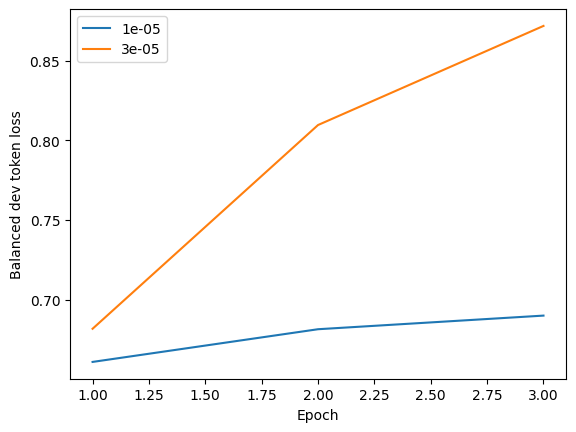

Chosen model: runs/lr_1e-05/best
Reload verification: {
  "same_three_outputs": true,
  "full_model": true,
  "adapter_used": false
}


In [5]:
import matplotlib.pyplot as plt
selection=json.loads((work/'runs/selected_model.json').read_text(encoding='utf-8'))
for result in selection['runs']:
    history=result['history']
    plt.plot([r['epoch'] for r in history],[r['dev']['balanced'] for r in history],label=str(result['lr']))
plt.xlabel('Epoch');plt.ylabel('Balanced dev token loss');plt.legend();plt.show()
print('Chosen model:',selection['winner']['model_dir'])
print('Reload verification:',(work/'runs/reload_verification.json').read_text())